In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MPL_NUM_THREADS"] = "1"

import numpy as np
rng = np.random.default_rng()
from point_lens import PointLens
from scipy.optimize import minimize
from scipy.signal import find_peaks
from scipy.interpolate import make_splprep
from scipy.integrate import trapezoid
from tqdm import tqdm

import matplotlib.pyplot as plt
from matplotlib import rc, rcParams
from cycler import cycler
my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
rc_params = {'axes.labelsize': 14,
             'axes.titlesize': 14,
             'legend.fontsize': 14,
             'xtick.labelsize': 12,
             'ytick.labelsize': 12,
             'text.usetex' : True,
             'text.latex.preamble' : '\\usepackage{txfonts}',
             'font.size': 14,
             'font.family': 'serif',
             'font.serif': 'times',
             'mathtext.default': 'sf',
             'lines.markeredgewidth' : 1,
             'lines.linewidth' : 2,
             'axes.prop_cycle' : cycler(color=my_colors),
            }
rcParams.update(rc_params)

# Isolated Point Lens

In [2]:
L = PointLens(1e5)

## Basic geometry checks

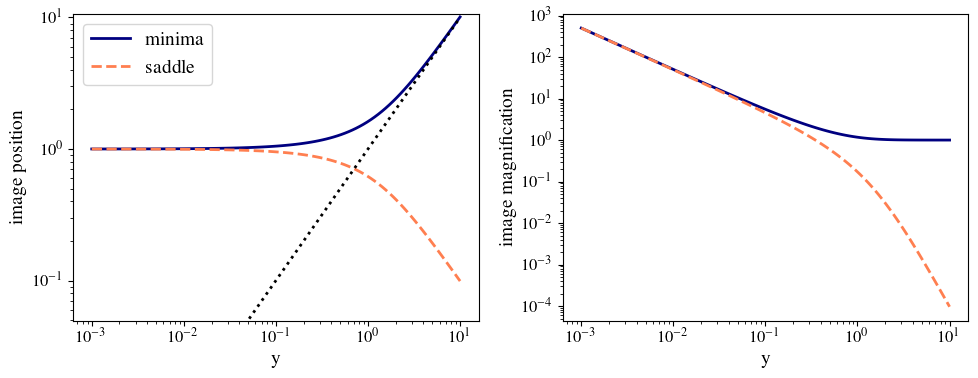

In [3]:
y_arr = np.geomspace(1e-3, 1e1, 100)
i1 = L.minimum_image(y_arr)
i2 = L.saddle_image(y_arr)

plt.figure(figsize=(10,4))
plt.subplot(121)
plt.plot(y_arr, i1.x, label='minima')
plt.plot(y_arr, -i2.x, ls='--', label='saddle')
plt.plot(y_arr, y_arr, ls=':', color='k')
plt.ylim(-i2.x.max() / 2, None)
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('y')
plt.ylabel('image position')

plt.subplot(122)
plt.plot(y_arr, i1.mu)
plt.plot(y_arr, -i2.mu, ls='--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('y')
plt.ylabel('image magnification')

plt.tight_layout()
plt.show()

## Amplification factor

In [4]:
w = np.geomspace(1e-3, 1e2, 1000)
f = L.w_to_f(w)
y = 5
mu_p, mu_m = L.magnifications(y)
dT_pm = L.time_delay(y)

Fw = L.amplification(f, y)
Fg = L.geometric_optics_amplification(f, y)

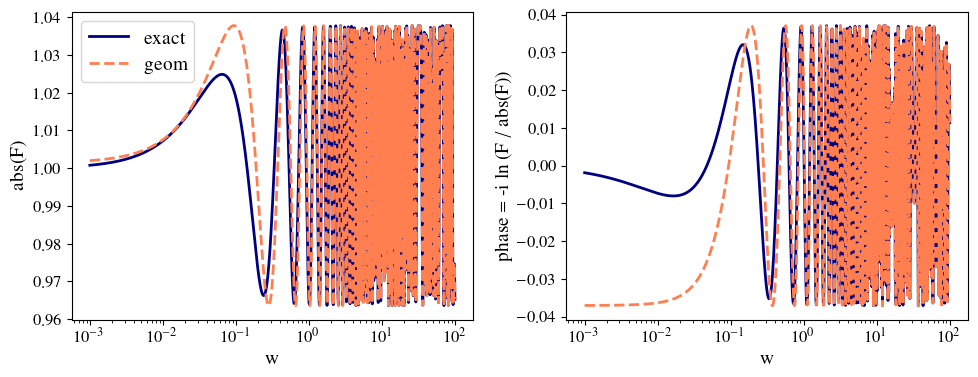

In [5]:
plt.figure(figsize=(10,4))
plt.subplot(121)
plt.plot(w, np.abs(Fw), label='exact')
plt.plot(w, np.abs(Fg), ls='--', label='geom')
plt.legend()
plt.xscale('log')
plt.xlabel('w')
plt.ylabel('abs(F)')

plt.subplot(122)
plt.plot(w, np.real(-1j * np.log(Fw / np.abs(Fw))))
plt.plot(w, np.real(-1j * np.log(Fg / np.abs(Fg))), ls='--')
plt.xscale('log')
plt.xlabel('w')
plt.ylabel('phase = -i ln (F / abs(F))')

plt.tight_layout()
plt.show()

### Modelling the amplification factor
We want to express F(f) in terms of functions of f that are smoothly varying.

Teja's suggestion is that a decomposition like $G(f) + ie^{2\pi i f \Delta T}H(f)$, where G and H incorporate contributions from near the two images, should work. In geometric limit, these just become (complex) constants, and they are smooth functions in the wave limit, so hopefully they smoothly reach the geometric limit.

To find G and H, he suggested going beyond the geometric optics approximation, and then stitching the exact wave solution at some matching frequency (IMRPhenom style).

I am trying a different, more brute force approach.

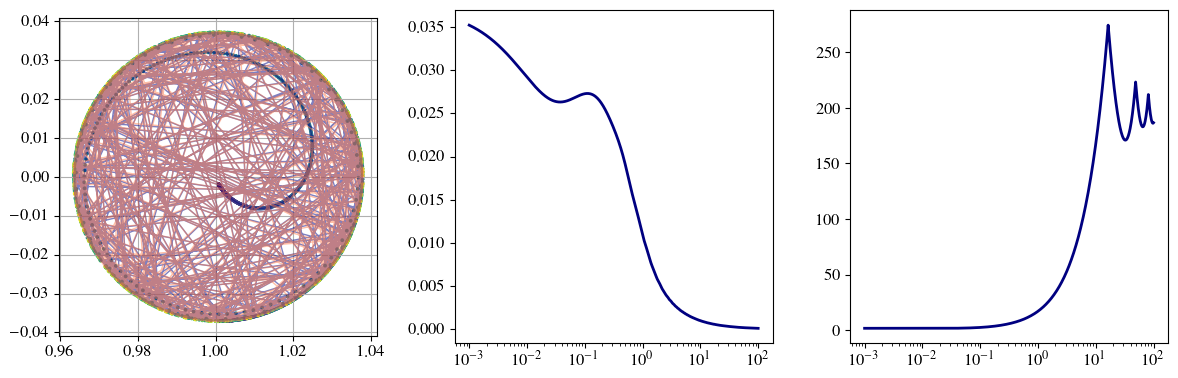

In [6]:
plt.figure(figsize=(12,4))
plt.subplot(131)
plt.scatter(np.real(Fw), np.imag(Fw), c=np.log10(w), s=3, cmap='viridis')
plt.scatter(np.real(Fg), np.imag(Fg), c=np.log10(w), s=2, cmap='viridis')
plt.plot(np.real(Fw), np.imag(Fw), alpha=0.5, lw=1, color='C0')
plt.plot(np.real(Fg), np.imag(Fg), alpha=0.5, lw=1, color='C1')
plt.grid()
plt.gca().set_aspect('equal')

plt.subplot(132)
plt.plot(w, np.abs(Fw - Fg))
plt.xscale('log')

plt.subplot(133)
plt.plot(w, np.unwrap(np.angle(Fw - Fg)))
plt.xscale('log')

plt.tight_layout()
plt.show()

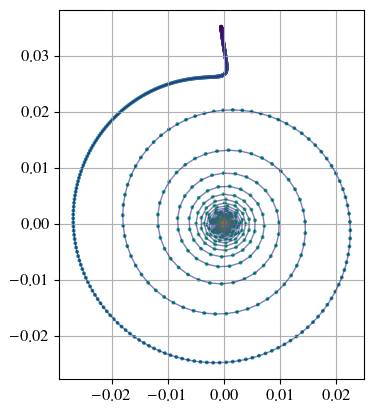

In [7]:
# %matplotlib widget
# plt.close('all')

G = Fw - Fg # variation in shift when circle is fixed
plt.scatter(np.real(G), np.imag(G), c=np.log10(w), s=3, cmap='viridis')
plt.plot(np.real(G), np.imag(G), alpha=0.5, lw=1, color='C0')
plt.grid()
plt.gca().set_aspect('equal')
plt.show()

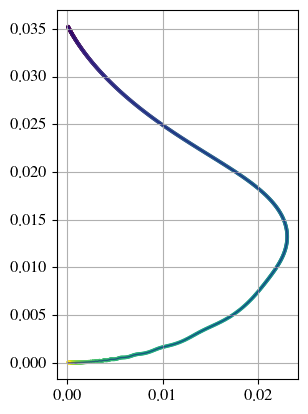

In [8]:
# %matplotlib widget
# plt.close('all')

H = (Fw - mu_p**0.5) / np.exp(1j * w * dT_pm) + 1j * (-mu_m)**0.5 # variation in circle when shift is fixed
plt.scatter(np.real(H), np.imag(H), c=np.log10(w), s=3, cmap='viridis')
plt.plot(np.real(H), np.imag(H), alpha=0.5, lw=1, color='C0')
plt.grid()
plt.gca().set_aspect('equal')
plt.show()

#### Remarks
$$F(\omega) = G(\omega) + H(\omega)~e^{i\omega \Delta T}$$
$G(\omega)$ and $H(\omega)$ are complex functions which approach $\sqrt{\mu_+}$ and $-i\sqrt{-\mu_-}$ as $\omega \rightarrow \infty$.

There is quite a bit of freedom in choosing these functions. If we choose to fix either of $G(\omega)$ or $H(\omega)$ to their asymptotic value, the other shows oscillatory behavior.

However, after the first, or maybe second round, they closely resemble an inspiralling ellipse. An inspiralling ellipse can be fully described by a few complex constants, along with a modulation by a steadily changing phase. But my initial experiments showed it to be quite a difficult thing to fit, especially while ensuring the inital wave-optics match.

Here is an alternative approach to try: we conjecture (or hope) that allowing both $G(\omega)$ and $H(\omega)$ to be free (unlike before where I was fixing one and fitting the other) will result in both taking a simple, non-oscillatory form that can be fitted with 2 cubic splines with two-four pieces. Each spline is in 2D (Re, Im), parameterized by $\log_{10}\omega$. There is some freedom still left (like the overall phase) that I will try removing by hand.

The fit would go as follows:
* Start with a guess cubic spline (i.e., guess values of the control points, knot vector, and coefficients in 2D) for $H(\omega)$
  - Fix the first control point at $(0, \mathrm{Im}(F(\omega_{min})))$ where $\omega_{min}$ is the smallest value of $\omega$ at which we have the data from the true $F(\omega)$.
  - Fix the last control point at $(0, \mathrm{Im}(F(\omega_{max})))$ where $\omega_{max}$ is the largest value of $\omega$ at which we have the data from the true $F(\omega)$. $\mathrm{Im}(F(\omega_{max})$ would be very close to $-\sqrt{-\mu_-}$, but we can let the data decide instead of setting it equal to geometric optics by hand.
  - The above choices automatically fix the first and last control points of $G(\omega)$ at $(\mathrm{Re}(F(\omega_{min})), 0)$ and $(\mathrm{Re}(F(\omega_{max})), 0)$ respectively. This removes the freedom in overall phase of these functions.
* Evaluate $G(\omega) = F(\omega) - H(\omega)~e^{i\omega \Delta T}$
* Find the length of $G(\omega) = re^{i\theta}$ curve in the complex plane, with extra cost $b$ for more bending (a hyperparamter of optimization) $$S = \int_{\omega_{min}}^{\omega_{max}} \sqrt{\dot{r}^2 + b r^2\dot{\theta}^2} ~ d\omega$$
* Fit $G(\omega)$ with a cubic spline with two-four pieces, call it $\hat{G}(\omega)$, with its length $\hat{S}$
* Define loss $$\mathcal{L} = S + \hat{S} + \int_{\omega_{min}}^{\omega_{max}} \left| G - \hat{G} \right|^2 ~ d\omega$$
* Update $H(\omega)$ guess spline to minimize $\mathcal{L}$

In [9]:
def find_length(Z, t, b=1):
    """
    Length of a complex curve parameterized by t
    If Z(t) = r(t) ~ e^{i\theta(t)}
    Length = \int_{t_{min}}^{t_{max}} \sqrt{\dot{r}^2 + b r^2\dot{\theta}^2} ~ dt
    b adds extra cost for bendy curves
    """
    r, theta = np.abs(Z), np.angle(Z)
    rdot = np.gradient(r, t)
    thetadot = np.gradient(theta, t)
    return trapezoid(rdot**2.0 + b * r**2.0 * thetadot**2.0, t)

def params_to_Hspl(params):
    Hre = np.concatenate([[Hre_ends[0]], params[::2], [Hre_ends[1]]])
    Him = np.concatenate([[Him_ends[0]], params[1::2], [Him_ends[1]]])
    Hspl = make_splprep(np.vstack([Hre,Him]), u=Hu, k=3, s=0)[0]
    return Hspl

In [10]:
def Loss(params):
    # Fw, w need to be globally defined
    # params should have length 3(n+1) where n is the number
    #  of spline pieces in H
    
    # Construct guess spline for H from optimizable params
    Hhat = params_to_Hspl(params)(np.log10(w))

    G = Fw - (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)
    # Gspl = make_splprep(np.vstack([G.real,G.imag]), u=np.log10(w), k=3, s=1e-4, nest=18)[0]
    # Ghat = Gspl(np.log10(w))
    # Fwhat = (Ghat[0,:] + 1j * Ghat[1,:]) + (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)
    # r = Fw - Fwhat

    L = find_length(G, np.log10(w)) #+ trapezoid(np.abs(r)**2.0, w)
    return L

In [11]:
n_Hspl = 10
Hre_ends = [0,0]
Him_ends = [-(-mu_m)**0.5, -(-mu_m)**0.5]
Hu = np.linspace(0, 1, n_Hspl + 3)**0.5
Hu = Hu * (np.log10(w[-1]) - np.log10(w[0])) + np.log10(w[0])
# Hu = np.linspace(np.log10(w[0]), np.log10(w[-1]), n_Hspl + 3)
params0 = rng.random((2 * (n_Hspl + 1)))
bounds = [[None,None] for _ in range(2 * (n_Hspl + 1))]

sol = minimize(Loss, x0=params0, bounds=bounds)
print(sol)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.0006298674972256346
        x: [ 9.400e-03 -2.271e-02 ...  1.768e-04 -3.711e-02]
      nit: 99
      jac: [ 3.445e-04  1.971e-04 ... -3.654e-04 -1.116e-04]
     nfev: 2369
     njev: 103
 hess_inv: <22x22 LbfgsInvHessProduct with dtype=float64>


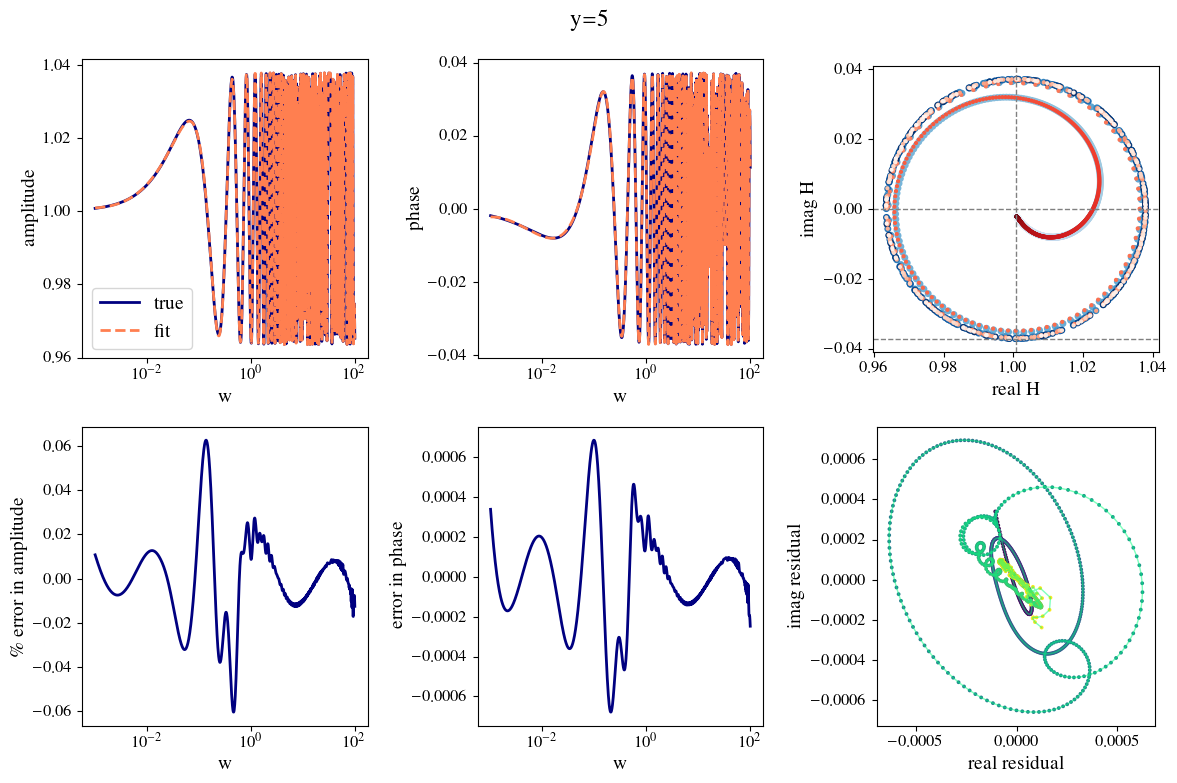

In [12]:
Hhat = params_to_Hspl(sol.x)(np.log10(w))
G = Fw - (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)
Gspl = make_splprep(np.vstack([G.real,G.imag]), u=np.log10(w), k=3, s=1e-4, nest=18)[0]
Ghat = Gspl(np.log10(w))
Fwhat = (Ghat[0,:] + 1j * Ghat[1,:]) + (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)
r = Fw - Fwhat

plt.figure(figsize=(12,8))
plt.subplot(231)
plt.plot(w, np.abs(Fw), label='true')
plt.plot(w, np.abs(Fwhat), ls='--', label='fit')
plt.xlabel('w')
plt.xscale('log')
plt.ylabel('amplitude')
plt.legend()

plt.subplot(232)
plt.plot(w, np.angle(Fw))
plt.plot(w, np.angle(Fwhat), ls='--')
plt.xlabel('w')
plt.xscale('log')
plt.ylabel('phase')

plt.subplot(233)
plt.scatter(Fw.real, Fw.imag, c=np.log10(w), s=16, cmap='Blues')
# plt.plot(Fw.real, Fw.imag, alpha=0.5, lw=1, color='C0')
plt.scatter(Fwhat.real, Fwhat.imag, c=np.log10(w), s=4, cmap='Reds_r')
# plt.plot(Fwhat.real, Fwhat.imag, alpha=0.5, lw=1, color='C1', ls='--')
plt.axvline(x=(mu_p)**0.5, ls='--', lw=1, color='gray')
plt.axhline(y=-(-mu_m)**0.5, ls='--', lw=1, color='gray')
plt.axhline(y=0, ls='--', lw=1, color='gray')
plt.gca().set_aspect('equal')
plt.xlabel('real H')
plt.ylabel('imag H')

plt.subplot(234)
plt.plot(w, 100 * (np.abs(Fwhat) / np.abs(Fw) - 1))
plt.xscale('log')
plt.xlabel('w')
plt.ylabel('\% error in amplitude')

plt.subplot(235)
plt.plot(w, np.angle(Fw) - np.angle(Fwhat))
plt.xscale('log')
plt.xlabel('w')
plt.ylabel('error in phase')

plt.subplot(236)
plt.scatter(np.real(r), np.imag(r), c=np.log10(w), s=3, cmap='viridis')
plt.plot(np.real(r), np.imag(r), alpha=0.5, lw=1, color='C4')
plt.xlabel('real residual')
plt.ylabel('imag residual')
plt.gca().set_aspect('equal')

plt.suptitle(f'y={y}')
plt.tight_layout()
plt.show()

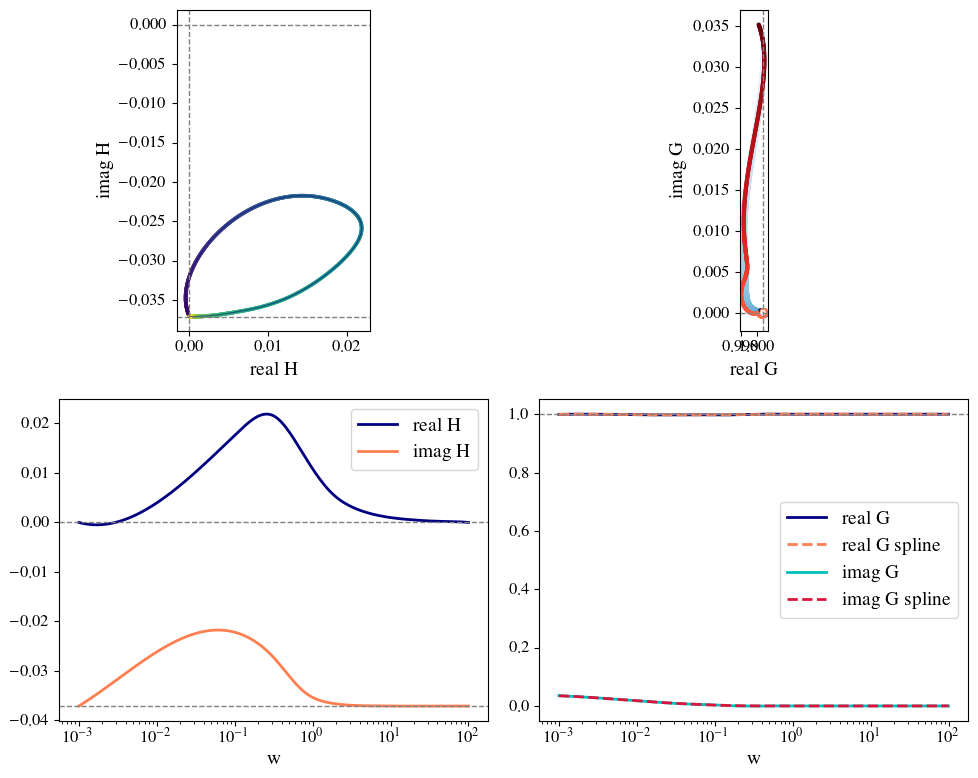

In [13]:
plt.figure(figsize=(10,8))
plt.subplot(221)
plt.scatter(Hhat[0,:], Hhat[1,:], c=np.log10(w), s=3, cmap='viridis')
plt.plot(Hhat[0,:], Hhat[1,:], alpha=0.5, lw=1, color='C0')
plt.axhline(y=-(-mu_m)**0.5, ls='--', lw=1, color='gray')
plt.axhline(y=0, ls='--', lw=1, color='gray')
plt.axvline(x=0, ls='--', lw=1, color='gray')
plt.gca().set_aspect('equal')
plt.xlabel('real H')
plt.ylabel('imag H')

plt.subplot(222)
plt.scatter(Ghat[0,:], Ghat[1,:], c=np.log10(w), s=16, cmap='Blues')
# plt.plot(Ghat[0,:], Ghat[1,:], alpha=0.5, lw=1, color='C0')
plt.scatter(np.real(G), np.imag(G), c=np.log10(w), s=4, cmap='Reds_r')
# plt.plot(np.real(G), np.imag(G), alpha=0.5, lw=1, color='C1')
plt.axhline(y=0, ls='--', lw=1, color='gray')
plt.axvline(x=(mu_p)**0.5, ls='--', lw=1, color='gray')
plt.gca().set_aspect('equal')
plt.xlabel('real G')
plt.ylabel('imag G')

plt.subplot(223)
plt.plot(w, Hhat[0,:], label='real H')
plt.plot(w, Hhat[1,:], label='imag H')
plt.legend()
plt.axhline(y=-(-mu_m)**0.5, ls='--', lw=1, color='gray')
plt.axhline(y=0, ls='--', lw=1, color='gray')
plt.xlabel('w')
plt.xscale('log')

plt.subplot(224)
# plt.plot(w, np.abs(G), label='G')
# plt.plot(w, np.abs(Ghat[0,:] + 1j * Ghat[1,:]), label='spline', ls='-')
plt.plot(w, np.real(G), label='real G')
plt.plot(w, Ghat[0,:], label='real G spline', ls='--')
plt.plot(w, np.imag(G), label='imag G')
plt.plot(w, Ghat[1,:], label='imag G spline', ls='--')
plt.legend()
plt.axhline(y=(mu_p)**0.5, ls='--', lw=1, color='gray')
plt.xlabel('w')
plt.xscale('log')

plt.tight_layout()
plt.show()

In [15]:
w = np.geomspace(1e-3, 1e2, 1000)
f = L.w_to_f(w)

n_Hspl = 10
Hre_ends = [0,0]
Hu = np.linspace(0, 1, n_Hspl + 3)**0.5
Hu = Hu * (np.log10(w[-1]) - np.log10(w[0])) + np.log10(w[0])
bounds = [[None,None] for _ in range(2 * (n_Hspl + 1))]
params0 = rng.random((2 * (n_Hspl + 1)))

y_arr = np.geomspace(1e-2, 1e1, 100)[::-1]
fit_data = []

for y in tqdm(y_arr):
    mu_p, mu_m = L.magnifications(y)
    dT_pm = L.time_delay(y)
    Fw = L.amplification(f, y)
    
    Him_ends = [-(-mu_m)**0.5, -(-mu_m)**0.5]
    
    sol = minimize(Loss, x0=params0, bounds=bounds)
    params0 = sol.x # so that next opti can start with a close enough solution

    Hspl = params_to_Hspl(sol.x)
    Hhat = Hspl(np.log10(w))
    G = Fw - (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)
    Gspl = make_splprep(np.vstack([G.real,G.imag]), u=np.log10(w), k=3, s=1e-4, nest=18)[0]
    Ghat = Gspl(np.log10(w))
    Fwhat = (Ghat[0,:] + 1j * Ghat[1,:]) + (Hhat[0,:] + 1j * Hhat[1,:]) * np.exp(1j * w * dT_pm)

    dAmp = np.abs(Fwhat) / np.abs(Fw) - 1
    dphi = np.angle(Fwhat) - np.angle(Fw)
    
    fit_data.append({'Hspl':Hspl, 'Gspl':Gspl,
                     'integrated relative amplitude error':trapezoid(np.abs(dAmp), np.log10(w)),
                     'maximum relative amplitude error':np.max(np.abs(dAmp)),
                     'integrated phase error':trapezoid(dphi, np.log10(w)),
                     'integrated absolute phase error':trapezoid(np.abs(dphi), np.log10(w)),
                     'maximum absolute phase error':np.max(np.abs(dphi))})

100%|█████████████████████████████████████████| 100/100 [01:40<00:00,  1.01s/it]


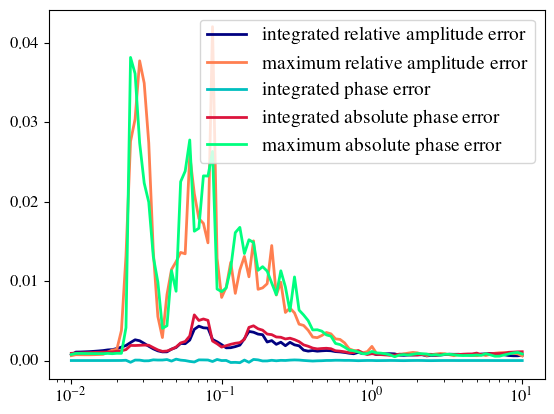

In [16]:
for key in fit_data[0].keys():
    if 'spl' in key:continue
    plt.plot(y_arr, [fit_data[i][key] for i in range(len(y_arr))], label=key)
plt.xscale('log')
plt.legend()
plt.show()

/tmp/ipykernel_12107/1592907342.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


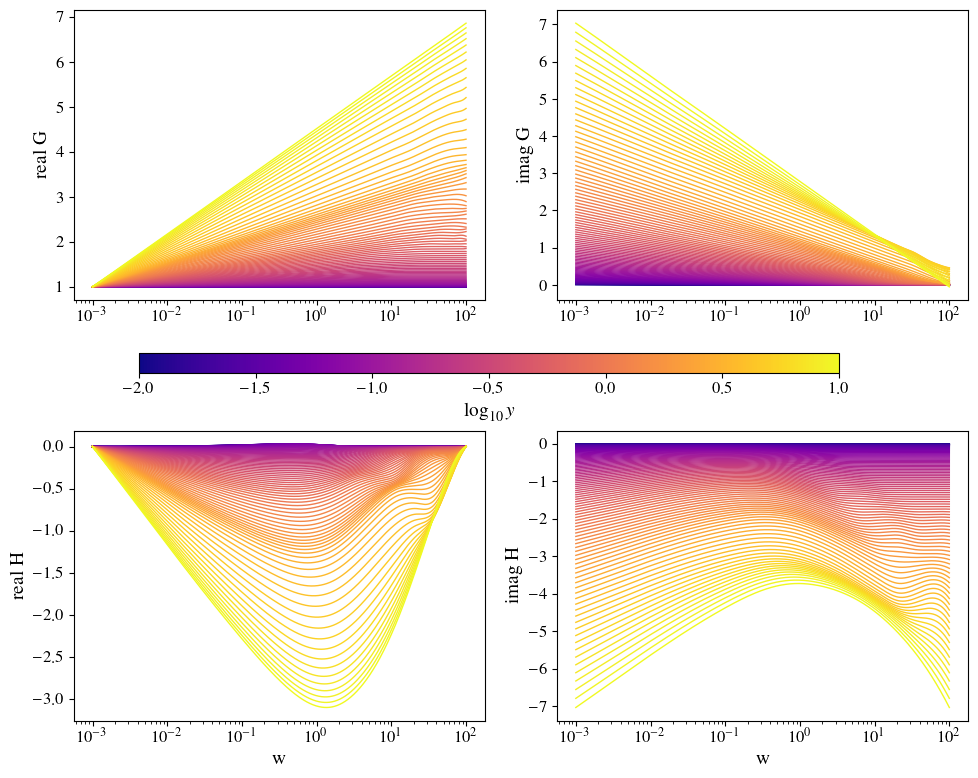

In [17]:
cmap = plt.get_cmap('plasma')
fig, ax = plt.subplots(2,2,figsize=(10,8))
for i in range(len(y_arr)):
    Hhat = fit_data[i]['Hspl'](np.log10(w))
    Ghat = fit_data[i]['Gspl'](np.log10(w))

    ax[0][0].plot(w, Ghat[0,:], color=cmap(i / (len(y_arr) - 1)), lw=1)
    ax[0][1].plot(w, Ghat[1,:], color=cmap(i / (len(y_arr) - 1)), lw=1)
    ax[1][0].plot(w, Hhat[0,:], color=cmap(i / (len(y_arr) - 1)), lw=1)
    ax[1][1].plot(w, Hhat[1,:], color=cmap(i / (len(y_arr) - 1)), lw=1)

for i in range(2):
    for j in range(2):
        ax[i][j].set_xscale('log')
        ax[1][j].set_xlabel('w')
        
ax[0][0].set_ylabel('real G')
ax[0][1].set_ylabel('imag G')
ax[1][0].set_ylabel('real H')
ax[1][1].set_ylabel('imag H')

cax = fig.add_axes([0.15, 0.52, 0.70, 0.025])
sc = cax.scatter([],[], c=[], cmap=cmap, vmin=np.log10(y_arr.min()), vmax=np.log10(y_arr.max()))
fig.colorbar(sc, ax=ax, cax=cax, orientation='horizontal', label=r'$\log_{10} y$')

plt.tight_layout()
plt.subplots_adjust(hspace=0.45)
plt.show()

In [ ]:
avada kedavra

In [ ]:
# %matplotlib inline
    
plt.plot(w, np.abs(G))
plt.plot(w, np.abs(H), ls='--')
plt.plot(w, 0.01 * np.sin(w * dT_pm))
plt.yscale('log')
plt.show()

That, to me, looks like an inspiral, and, in the leading order, should be possible to model by a precessing ellipse with a smoothly decaying amplitude.

In [ ]:
# Generic precessing ellipse with smooth amplitude, in the complex plane
def inspiralling_precessing_ellipse(s, A, f, p, e, w, W, z0):
    """
    s: parameterizes the curve, units of time
    A: function, returns a real valued amplitude at a given s
    f: real, shifts the ellipse to f * 2 * e**0.5,
        if f=2 * e**0.5, this pushes inspiral towards a focus instead of the center
        # FIXME: promote this to a func of s
    p: normalized phase offset, real
    e: eccentricity, real
    w: precession frequency, real
    W: orbital frequency, real
    z0: overall translation offset, complex

    returns the complex coordinate z at a given s
    """

    phase_W = np.exp(1j * W * s)
    ellipse = (phase_W + e / phase_W) / (1 + e)
    prec = np.exp(1j * (w * s + 2 * np.pi * p))
    return z0 + A(s) * prec * (ellipse + f)

### Eyeball fit

# %matplotlib widget

r = Fw - Fg
plt.scatter(np.real(r), np.imag(r), c=np.log10(w), s=3, cmap='viridis')
plt.plot(np.real(r), np.imag(r), alpha=0.5, lw=1, color='C0')

def amp_func(s):
    sinv = 1. / s
    return 0.2 * sinv - 0.01 * sinv**2.0

R = inspiralling_precessing_ellipse(w[100:], amp_func=amp_func, f=1, p=0, e=0.1, w=0.1, W=1./dT_pm, z0=0)
plt.scatter(np.real(R), np.imag(R), c=np.log10(w[100:]), s=3, cmap='plasma')
plt.plot(np.real(R), np.imag(R), alpha=0.5, lw=1, color='C1')
plt.grid()
# plt.gca().set_aspect('equal')
plt.show()

In [ ]:
def find_mean_amplitude(w, r):
    A = np.abs(r)
    minima, _ = find_peaks(-A)
    w_mean, A_mean = [], []
    split_idx = [0,*minima,len(w)-1]
    for i,j in zip(split_idx[:-1], split_idx[1:]):
        w_mean.append(np.mean(w[i:j]))
        A_mean.append(np.mean(A[i:j]))
    return w_mean, A_mean

r = Fw - Fg
plt.plot(w, np.abs(r))
plt.plot(*find_mean_amplitude(w, r))
plt.xscale('log')
plt.yscale('log')
plt.show()

In [ ]:
def amplitude_func(s, params):
    x = np.log(s)
    l, logA0, x0 = params[:3]
    S = 1. / (1 + np.exp((x - x0) / l))
    logA = logA0 + l * np.log(np.polyval(params[3:], S))
    # S1S = S * (1 - S)
    # if len(params[3:]) != 0:
    #     logA = logA + S1S * params[3]
    #     S21 = 1.
    #     for p in params[4:]:
    #         S21 = S21 * (2 * S - 1)
    #         logA = logA + S21 * S1S * p
    return np.exp(logA)

In [ ]:
def loss(params):
    def A(s): return amplitude_func(s, params[4:])
    r = inspiralling_precessing_ellipse(w, A, *params[:4], W=1./dT_pm, z0=0)
    dA = np.abs(Fw) - np.abs(Fg + r)
    dphi = (np.angle(Fw) - np.angle(Fg + r)) / 2 / np.pi
    return np.mean(dA**2.0 + dphi**2.0 * np.abs(Fw))

In [ ]:
Hermite_degree = 4
sol = minimize(loss, x0=[1.,0.,0.,0.,*rng.random((4+Hermite_degree))],
# sol = minimize(loss, x0=[1.,0.,0.,0.,1,1,0,1,0.5,0.5,0.1,0.1],
               bounds=[[0,None],[0,1],[0,1e-1],[0,1e-6], [0,None], *[[None]*2]*(3+Hermite_degree)])
print(sol)

In [ ]:
# %matplotlib widget

r = Fw - Fg
plt.scatter(np.real(r), np.imag(r), c=np.log10(w).clip(-3,0), s=3, cmap='viridis')
plt.plot(np.real(r), np.imag(r), alpha=0.5, lw=1, color='C0')

def A(s): return amplitude_func(w, sol.x[4:])
    
zs = inspiralling_precessing_ellipse(w, A, *sol.x[:4], W=1./dT_pm, z0=0)
plt.scatter(np.real(zs), np.imag(zs), c=np.log10(w).clip(-3,0), s=3, cmap='viridis')
plt.plot(np.real(zs), np.imag(zs), alpha=0.5, lw=1, color='C0')
plt.grid()
plt.gca().set_aspect('equal')
plt.show()

In [ ]:
plt.plot(w, np.abs(r))
A = amplitude_func(w, sol.x[4:])
plt.plot(w, A / A[0] * np.abs(r)[0], ls='--')
plt.plot(w, A)
plt.plot(*find_mean_amplitude(w, r), ls=':')
plt.xscale('log')
plt.yscale('log')
plt.show()

In [ ]:
r1 = Fw - Fg - zs
plt.scatter(np.real(r1), np.imag(r1), c=np.log10(w), s=3, cmap='viridis')
plt.plot(np.real(r1), np.imag(r1), alpha=0.5, lw=1, color='C0')

plt.grid()
# plt.gca().set_aspect('equal')
plt.show()

In [ ]:
plt.subplot(121)
plt.plot(w, np.abs(r1) / np.abs(Fw))
plt.plot(w, 0.01 * np.sin(w * dT_pm))
plt.yscale('log')

plt.subplot(122)
plt.plot(w, np.angle(r1) / np.angle(Fw))
plt.plot(w, 0.01 * np.sin(w * dT_pm))
plt.show()